#Customer Segmentation with RFM and KMeans
This project segments 4338 customers from the UCI Online Retail II dataset using RFM analysis. Recency is days since last purchase from 2011-12-10, Frequency is number of unique invoices, and Monetary is total spend. After cleaning 541,909 rows, I applied log1p and StandardScaler, then used the Elbow Method to select K=4.
 The result is 4 segments: Champions (716), New/Promising (837), Regulars (1173), and At-Risk/Lost (1612). The goal is to help the business retain valuable customers and win back lost ones.

In [1]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
df = pd.read_excel(url)
print(df.shape)
print(df.head())
print(df.info())

(541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------      

# Task 2 - Customer Segmentation Analysis
Online Retail - RFM + KMeans Clustering

In [5]:
# Cleaning
df = df.dropna(subset=['CustomerID'])
print("After dropping missing CustomerID:", df.shape)
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
print("After cleaning:", df.shape)
print(df['TotalPrice'].describe())
print("Unique customers:", df['CustomerID'].nunique())

After dropping missing CustomerID: (406829, 8)
After cleaning: (397884, 9)
count    397884.000000
mean         22.397000
std         309.071041
min           0.001000
25%           4.680000
50%          11.800000
75%          19.800000
max      168469.600000
Name: TotalPrice, dtype: float64
Unique customers: 4338


In [6]:
# RFM Calculation
import pandas as pd

# Reference date = day after last transaction
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Reference date:", reference_date)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']
print(rfm.head())
print(rfm.describe())

Reference date: 2011-12-10 12:50:00
            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2054.266460
std     100.014169     7.697998    8989.230441
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     307.415000
50%      51.000000     2.000000     674.485000
75%     142.000000     5.000000    1661.740000
max     374.000000   209.000000  280206.020000


In [7]:
# Log transform + Scaling for KMeans
import numpy as np
from sklearn.preprocessing import StandardScaler

# Log transform to reduce skew (Monetary is very skewed)
rfm_log = np.log1p(rfm)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled = pd.DataFrame(rfm_scaled, index=rfm.index, columns=rfm.columns)

print(rfm_scaled.head())
print(rfm_scaled.describe())

             Recency  Frequency  Monetary
CustomerID                               
12346.0     1.461993  -0.955214  3.706225
12347.0    -2.038734   1.074425  1.411843
12348.0     0.373104   0.386304  0.716489
12349.0    -0.623086  -0.955214  0.698739
12350.0     1.424558  -0.955214 -0.618962
            Recency     Frequency      Monetary
count  4.338000e+03  4.338000e+03  4.338000e+03
mean  -9.172520e-17 -7.206980e-17  2.882792e-16
std    1.000115e+00  1.000115e+00  1.000115e+00
min   -2.341296e+00 -9.552143e-01 -4.004574e+00
25%   -6.613615e-01 -9.552143e-01 -6.856676e-01
50%    8.992557e-02 -3.615828e-01 -6.218718e-02
75%    8.447915e-01  6.532370e-01  6.541861e-01
max    1.564198e+00  5.858535e+00  4.731591e+00


K=2, Inertia=6481
K=3, Inertia=4868
K=4, Inertia=3939
K=5, Inertia=3296
K=6, Inertia=2855
K=7, Inertia=2549
K=8, Inertia=2337
K=9, Inertia=2156
K=10, Inertia=2000


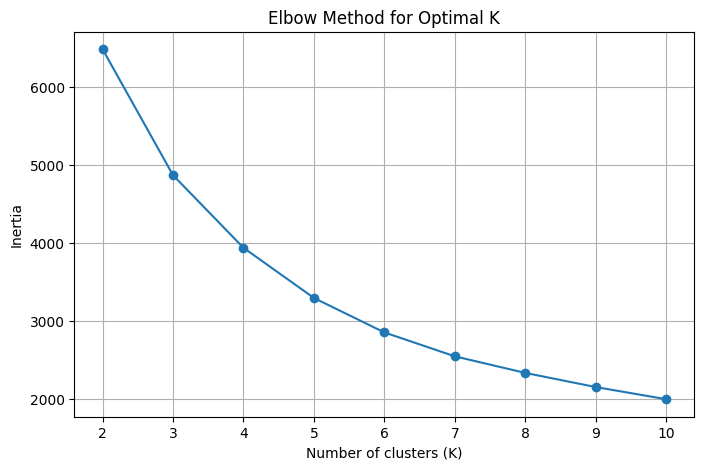

In [8]:
# Elbow Method to find best K
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertia.append(km.inertia_)
    print(f"K={k}, Inertia={km.inertia_:.0f}")

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.grid(True)
plt.show()

In [9]:
# Final KMeans with K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print(rfm['Cluster'].value_counts().sort_index())
print("\nCluster means (original RFM values):")
print(rfm.groupby('Cluster')[['Recency','Frequency','Monetary']].mean().round(1))

Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64

Cluster means (original RFM values):
         Recency  Frequency  Monetary
Cluster                              
0           18.1        2.1     551.8
1           12.1       13.7    8074.3
2           71.1        4.1    1802.8
3          182.5        1.3     343.5


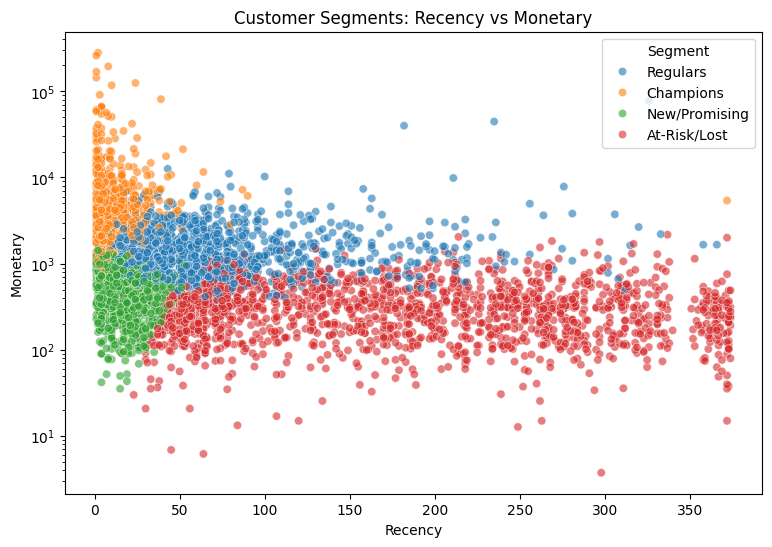

Segment
At-Risk/Lost     1612
Regulars         1173
New/Promising     837
Champions         716
Name: count, dtype: int64


In [10]:
# Name clusters + Visualize
cluster_names = {
    0: 'New/Promising',
    1: 'Champions',
    2: 'Regulars',
    3: 'At-Risk/Lost'
}
rfm['Segment'] = rfm['Cluster'].map(cluster_names)

# Scatter: Recency vs Monetary, colored by Segment
import seaborn as sns
plt.figure(figsize=(9, 6))
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Segment', alpha=0.6)
plt.title('Customer Segments: Recency vs Monetary')
plt.yscale('log')
plt.show()

print(rfm['Segment'].value_counts())

In [11]:
# Save final result
rfm.to_csv('rfm_segmented_customers.csv')
print("Saved! Shape:", rfm.shape)
print(rfm.head())

Saved! Shape: (4338, 5)
            Recency  Frequency  Monetary  Cluster        Segment
CustomerID                                                      
12346.0         326          1  77183.60        2       Regulars
12347.0           2          7   4310.00        1      Champions
12348.0          75          4   1797.24        2       Regulars
12349.0          19          1   1757.55        0  New/Promising
12350.0         310          1    334.40        3   At-Risk/Lost


Conclusion: KMeans with K=4 grouped 4338 customers into Champions, New/Promising, Regulars, and At-Risk/Lost. Champions are few but spend most. At-Risk/Lost are the largest group and need win-back. The business should focus retention on Champions and re-activation on At-Risk.